<center><h1>Chen_Sian_HW6</h1></center>
<br>
<br>

Name: Sian Chen
<br>
Github Username: Ryan6546ea
<br>
USC ID: 3132413754

## 1. Tree-Based Methods

Import packages

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as make_imb_pipeline

### (a) Download the APS Failure data

In [2]:
train_data = pd.read_csv("../data/aps_failure_training_set.csv", skiprows=20, na_values="na")
test_data = pd.read_csv("../data/aps_failure_test_set.csv", skiprows=20, na_values="na")

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common methods include mean, median, mode, KNN, and iterative imputation. I choose median imputation because it is simple, fast, and less sensitive to extreme values.

#### (ii) Calculate the coefficient of variation

In [3]:
X_train = train_data.drop(columns="class")

# Estimate medians from training data only to avoid leakage.
medians = X_train.median()
X_train_imputed = X_train.fillna(medians)

feature_cv = (
    X_train_imputed.std(ddof=1) / X_train_imputed.mean()
).sort_values(ascending=False)

print(feature_cv.to_string())

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dj_000    117.494225
ag_000     92.917755
as_000     87.332500
ay_009     84.733735
ak_000     80.424975
az_009     77.838544
ch_000     77.453857
au_000     68.882751
cr_000     58.078072
ay_001     52.824714
df_000     52.292814
dz_000     51.332228
ef_000     49.366659
cs_008     48.102206
aj_000     44.265996
eg_000     42.481747
dl_000     39.739088
ay_002     39.248654
dg_000     38.486162
ay_000     37.428285
dk_000     37.039123
cy_000     36.600908
dm_000     36.261403
ag_001     35.249314
ea_000     34.946519
cn_009     34.272052
ay_004     33.752345
ag_009     33.357567
da_000     29.367527
ay_003     28.735090
cn_000     26.335574
ae_000     24.200137
at_000     23.708187
az_008     22.679650
dq_000     22.030103
af_000     19.471295
ai_000     18.203806
ag_002     17.565907
az_007     16.229427
cl_000     14.970730
cz_000     14.505585
cp_000     13.933288
az_002     13

#### (iii) Plot a correlation matrix

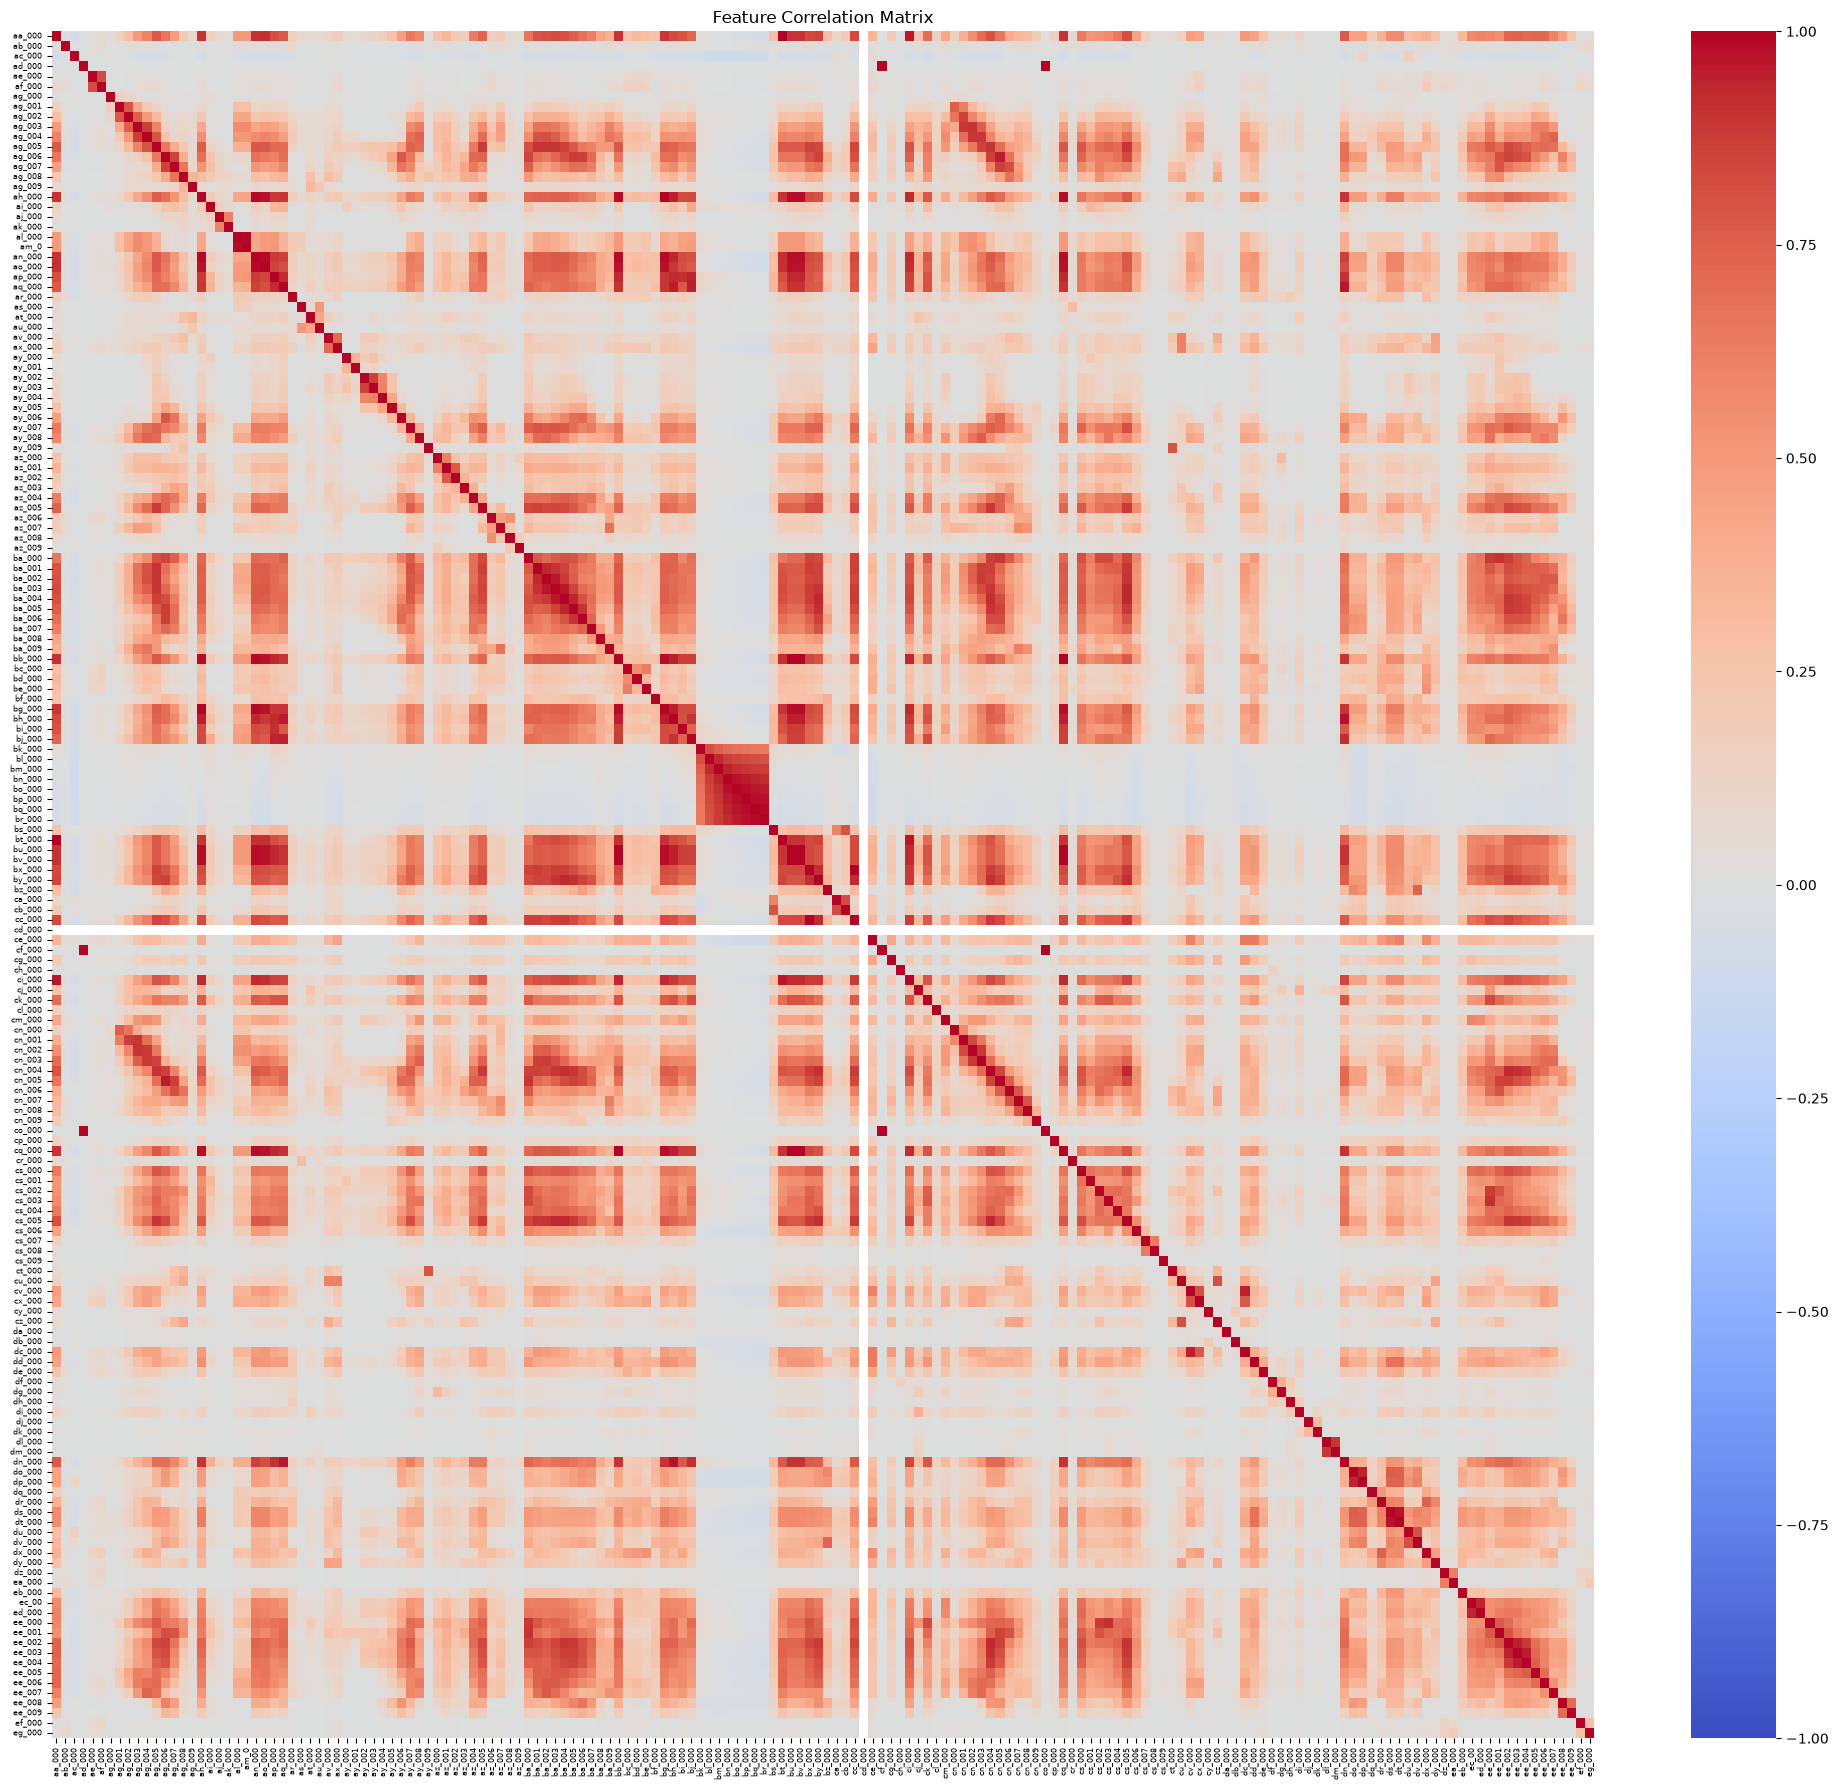

In [4]:
plt.figure(figsize=(20, 18))
sns.heatmap(
    X_train_imputed.corr(),
    cmap="coolwarm", vmin=-1, vmax=1,
    xticklabels=True, yticklabels=True
)
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

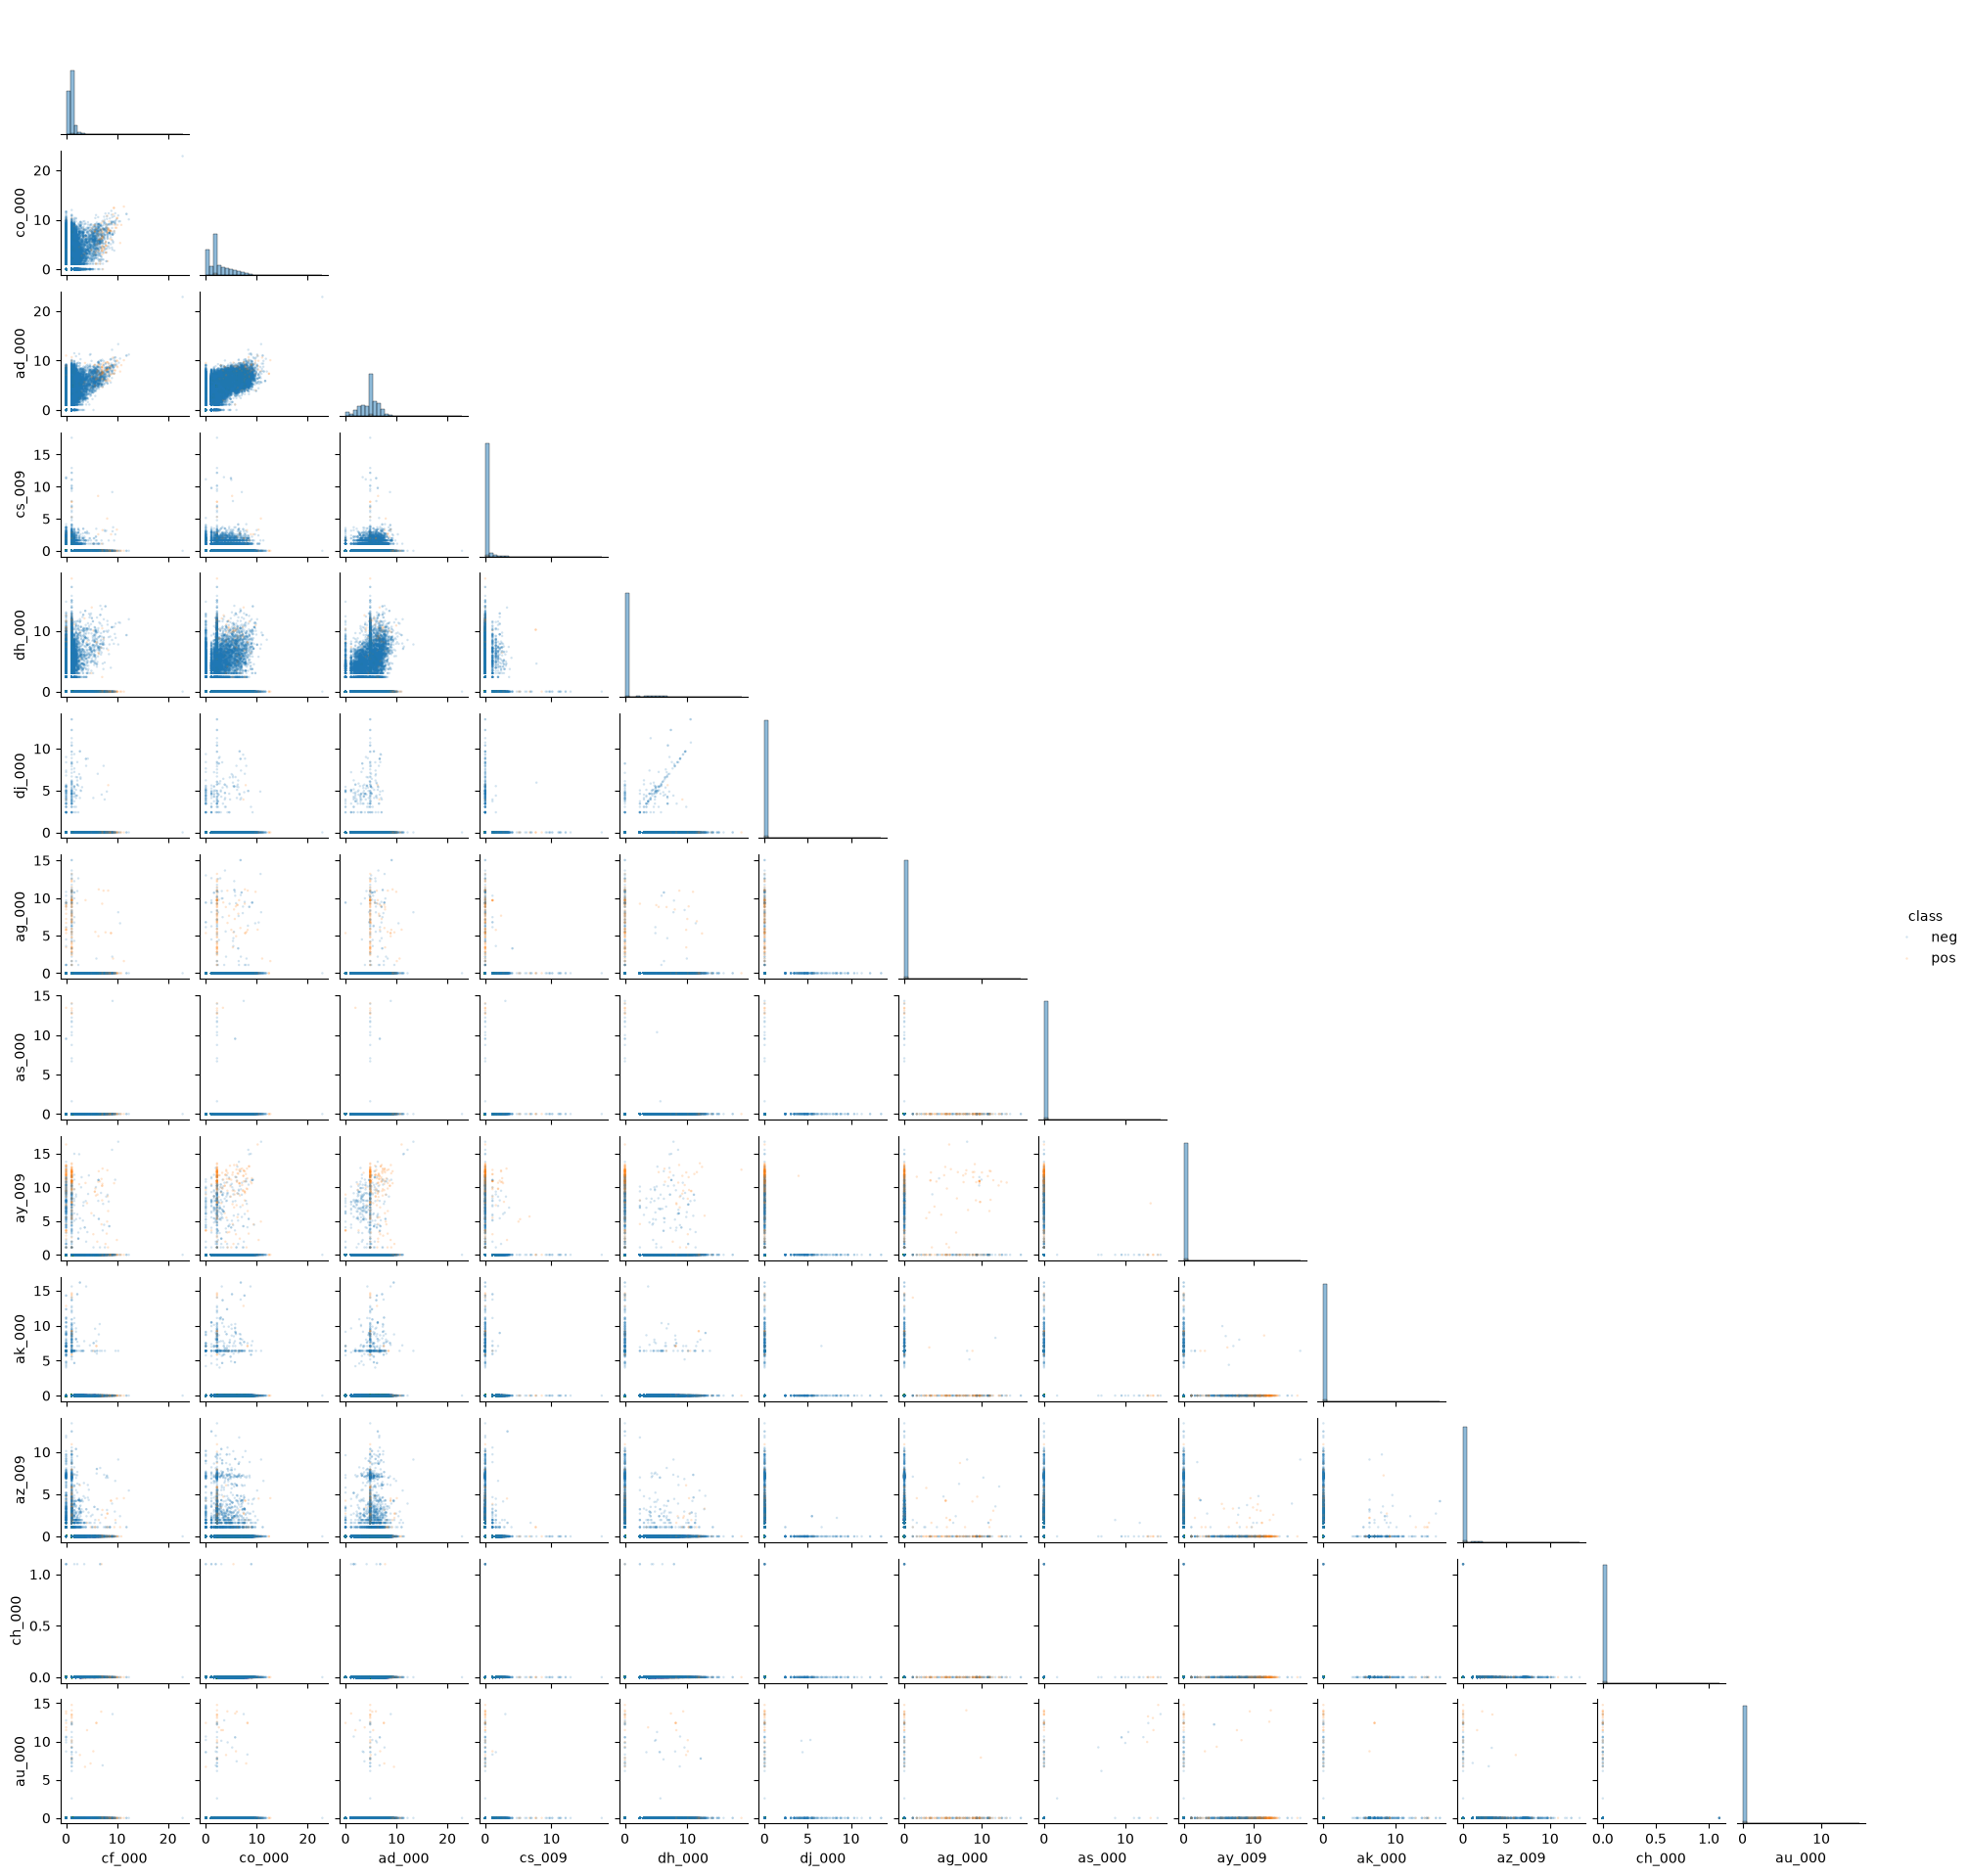

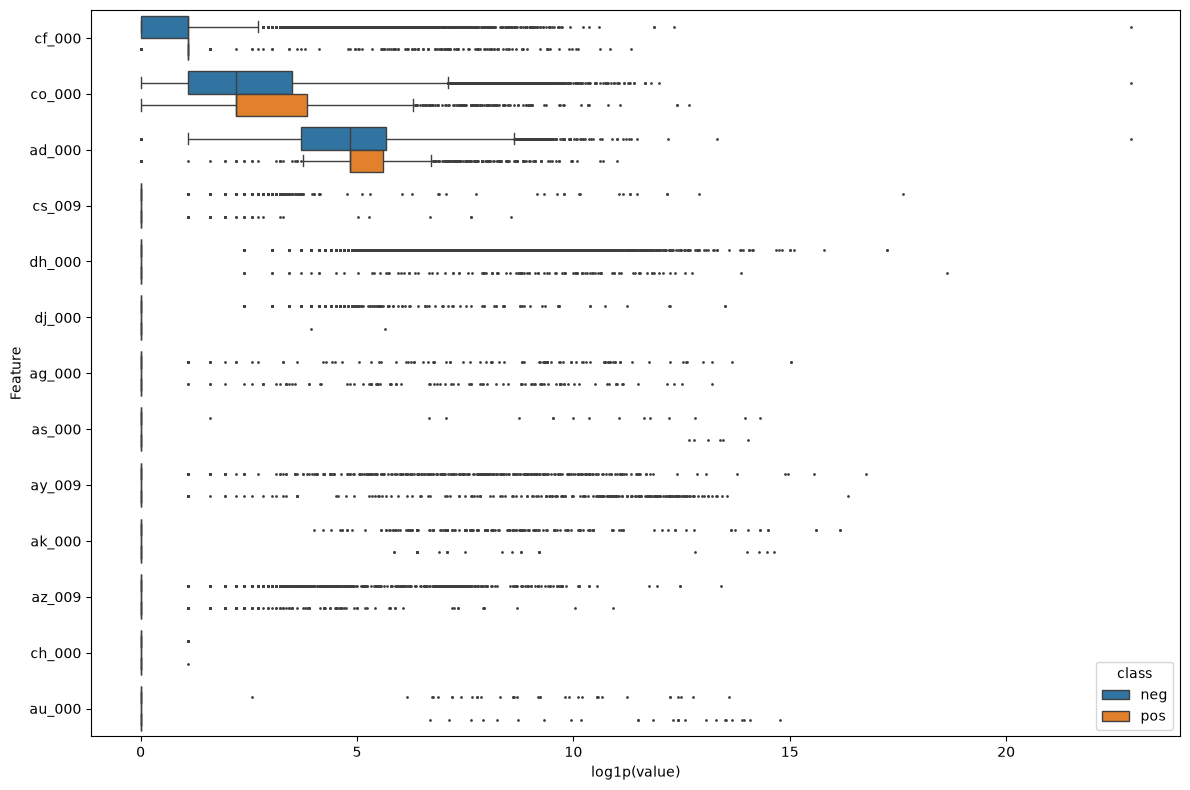

In [5]:
top_features = feature_cv.head(13).index

# Use log1p for plotting to display zeros and extreme values clearly.
plot_data = np.log1p(X_train_imputed[top_features])
plot_data["class"] = train_data["class"]

sns.pairplot(
    plot_data, hue="class", corner=True, diag_kind="hist", height=1.5,
    plot_kws={"s": 3, "alpha": 0.2, "edgecolor": "none"},
    diag_kws={"bins": 30}
)
plt.show()

plt.figure(figsize=(12, 8))
sns.boxplot(
    data=plot_data.melt(
        id_vars="class", var_name="Feature", value_name="log1p(value)"
    ),
    x="log1p(value)", y="Feature", hue="class", fliersize=1
)
plt.tight_layout()
plt.show()

Several features are mostly zero with a few extreme values. Scatter plots alone cannot establish statistical significance. High CV measures relative variability, not predictive importance.

#### (v) Is this data set imbalanced?

In [6]:
pd.DataFrame({
    "Training": train_data["class"].value_counts(),
    "Test": test_data["class"].value_counts()
})

,Training,Test
class,,
neg,59000,15625
pos,1000,375


Both sets are highly imbalanced. Positive cases account for only 1.67% of the training set and 2.34% of the test set.

### (c) Train a random forest

Training: error = 0.0017%, AUC = 1.0000
            Predicted neg  Predicted pos
Actual neg          59000              0
Actual pos              1            999
Test: error = 0.7562%, AUC = 0.9927
            Predicted neg  Predicted pos
Actual neg          15610             15
Actual pos            106            269


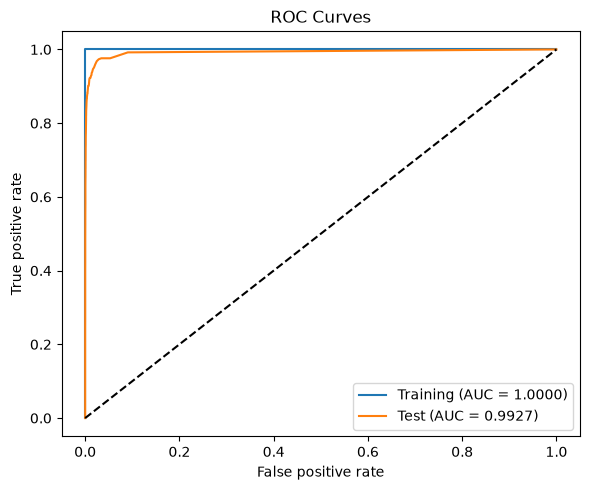

OOB error: 0.6167%


In [7]:
# Apply training-set medians to the test set.
X_test_imputed = test_data.drop(columns="class").fillna(medians)
y_train = train_data["class"]
y_test = test_data["class"]

rf = RandomForestClassifier(oob_score=True, random_state=42, n_jobs=-1)
rf.fit(X_train_imputed, y_train)

def evaluate_rf(model):
    plt.figure(figsize=(6, 5))
    for name, X, y in [
        ("Training", X_train_imputed, y_train),
        ("Test", X_test_imputed, y_test)
    ]:
        pred = model.predict(X)
        prob = model.predict_proba(X)[:, 1]
        auc = roc_auc_score(y, prob)

        print(f"{name}: error = {(pred != y).mean():.4%}, AUC = {auc:.4f}")
        print(pd.DataFrame(
            confusion_matrix(y, pred, labels=["neg", "pos"]),
            index=["Actual neg", "Actual pos"],
            columns=["Predicted neg", "Predicted pos"]
        ))

        fpr, tpr, _ = roc_curve(y, prob, pos_label="pos")
        plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("ROC Curves")
    plt.legend()
    plt.tight_layout()
    plt.show()

evaluate_rf(rf)
print(f"OOB error: {1 - rf.oob_score_:.4%}")

The training error is 0.0017%. The OOB error is 0.6167%, slightly below the test error of 0.7562%. Test AUC is 0.9927, but the model misses 106 of 375 positive cases. The low overall error therefore hides substantial missed failures.

### (d) Research class imbalance in random forest

Training: error = 0.0017%, AUC = 1.0000
            Predicted neg  Predicted pos
Actual neg          59000              0
Actual pos              1            999
Test: error = 1.1438%, AUC = 0.9904
            Predicted neg  Predicted pos
Actual neg          15606             19
Actual pos            164            211


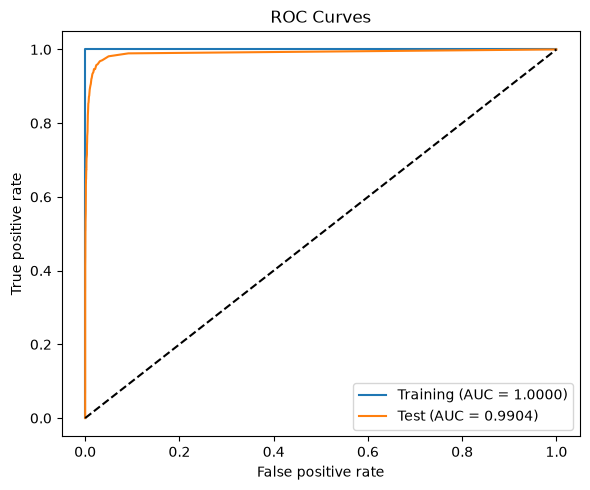

OOB error: 0.8017%


In [8]:
# Weight classes inversely to their frequency in each bootstrap sample.
rf_balanced = RandomForestClassifier(
    class_weight="balanced_subsample",
    oob_score=True, random_state=42, n_jobs=-1
)
rf_balanced.fit(X_train_imputed, y_train)

evaluate_rf(rf_balanced)
print(f"OOB error: {1 - rf_balanced.oob_score_:.4%}")

Class imbalance can be addressed with class weights or balanced sampling. Here, class weights are calculated separately within each bootstrap sample.

Compared with 1(c), test error increases from 0.7562% to 1.1438%, while AUC decreases from 0.9927 to 0.9904. OOB error rises from 0.6167% to 0.8017%, remaining below test error. Missed positive cases increase from 106 to 164. This weighting scheme did not improve performance on this test set.

### (e) XGBoost and Model Trees

Selected alpha: 0.01
Selection CV error: 0.6417%
Training: error = 0.0017%, AUC = 1.0000
            Predicted neg  Predicted pos
Actual neg          59000              0
Actual pos              1            999
Test: error = 0.7188%, AUC = 0.9931
            Predicted neg  Predicted pos
Actual neg          15597             28
Actual pos             87            288


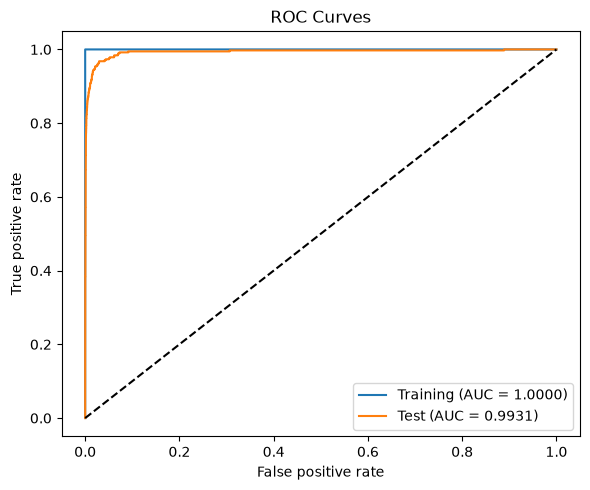

In [9]:
X_test = test_data.drop(columns="class")
y_train_binary = (y_train == "pos").astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Fit imputation separately within each training fold.
xgb_model = make_pipeline(
    SimpleImputer(strategy="median"),
    XGBClassifier(
        n_estimators=100, reg_lambda=0, tree_method="hist",
        random_state=42, n_jobs=4
    )
)

xgb_search = GridSearchCV(
    xgb_model,
    {"xgbclassifier__reg_alpha": [0, 0.01, 0.1, 1, 10, 100]},
    scoring="accuracy", cv=cv
).fit(X_train, y_train_binary)

print("Selected alpha:", xgb_search.best_params_["xgbclassifier__reg_alpha"])
print(f"Selection CV error: {1 - xgb_search.best_score_:.4%}")

def evaluate_xgb(model):
    plt.figure(figsize=(6, 5))
    for name, X, y in [
        ("Training", X_train, y_train),
        ("Test", X_test, y_test)
    ]:
        prob = model.predict_proba(X)[:, 1]
        pred = np.where(prob > 0.5, "pos", "neg")
        auc = roc_auc_score(y, prob)

        print(f"{name}: error = {(pred != y).mean():.4%}, AUC = {auc:.4f}")
        print(pd.DataFrame(
            confusion_matrix(y, pred, labels=["neg", "pos"]),
            index=["Actual neg", "Actual pos"],
            columns=["Predicted neg", "Predicted pos"]
        ))

        fpr, tpr, _ = roc_curve(y, prob, pos_label="pos")
        plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("ROC Curves")
    plt.legend()
    plt.tight_layout()
    plt.show()

evaluate_xgb(xgb_search)

I use XGBoost trees with L1 regularization on leaf weights. Five-fold CV selected alpha = 0.01. The selection CV error is 0.6417%, slightly below the test error of 0.7188%. Test AUC is 0.9931, but 87 of 375 positive cases are missed. The CV error was used for tuning and is not an independent performance estimate.

### (f) Use SMOTE to pre-process your data

Selected alpha: 0.01
Selection CV error: 0.6500%
Training: error = 0.0017%, AUC = 1.0000
            Predicted neg  Predicted pos
Actual neg          59000              0
Actual pos              1            999
Test: error = 0.6937%, AUC = 0.9940
            Predicted neg  Predicted pos
Actual neg          15578             47
Actual pos             64            311


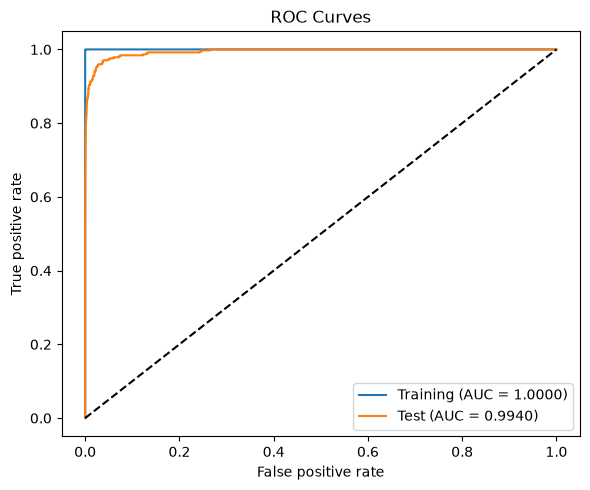

In [10]:
# Standardize features for SMOTE's distance-based neighbor selection.
smote_model = make_imb_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SMOTE(random_state=42),
    clone(xgb_model.named_steps["xgbclassifier"])
)

smote_search = GridSearchCV(
    smote_model, xgb_search.param_grid,
    scoring="accuracy", cv=cv
).fit(X_train, y_train_binary)

print("Selected alpha:", smote_search.best_params_["xgbclassifier__reg_alpha"])
print(f"Selection CV error: {1 - smote_search.best_score_:.4%}")

evaluate_xgb(smote_search)

CV selected alpha = 0.01, with a selection error of 0.6500%. Test error is 0.6937%, slightly above the CV error and below the 0.7188% in 1(e). Test AUC increases from 0.9931 to 0.9940. SMOTE reduces missed failures from 87 to 64 but increases false alarms from 28 to 47.

## 2. ISLR 6.6.3

(a) iv. Steadily decrease.
Increasing $s$ expands the feasible set, so training RSS cannot increase. It levels off once the least-squares solution becomes feasible.

(b) ii. Decrease initially, and then eventually increase in a U shape.
Test RSS typically decreases as reduced bias improves the fit, then increases as greater variance leads to overfitting.

(c) iii. Steadily increase.
Weaker regularization makes the fitted model more sensitive to changes in the training data, increasing variance.

(d) iv. Steadily decrease.
Relaxing the constraint allows a more flexible model, reducing squared bias.

(e) v. Remain constant.
Irreducible error comes from noise in the data-generating process and does not depend on $s$.

## 3. ISLR 6.6.5

Let $x_i=x_{i1}=x_{i2}$ for $i=1,2$, and assume $\lambda>0$. The intercept is zero.

(a) The ridge optimization problem is

$$
\min_{\beta_1,\beta_2}
\sum_{i=1}^{2}\left[y_i-x_i(\beta_1+\beta_2)\right]^2
+\lambda(\beta_1^2+\beta_2^2).
$$

(b) The RSS derivatives with respect to the two coefficients are identical. Subtracting the first-order conditions gives

$$
2\lambda(\hat\beta_1-\hat\beta_2)=0.
$$

Since $\lambda>0$, we obtain $\hat\beta_1=\hat\beta_2$.

(c) The lasso optimization problem is

$$
\min_{\beta_1,\beta_2}
\sum_{i=1}^{2}\left[y_i-x_i(\beta_1+\beta_2)\right]^2
+\lambda(|\beta_1|+|\beta_2|).
$$

(d) The RSS depends only on $t=\beta_1+\beta_2$. Also,

$$
|\beta_1|+|\beta_2|\ge |t|,
$$

with equality when the coefficients have the same sign or one is zero.

Let $\hat t$ minimize

$$
\sum_{i=1}^{2}(y_i-x_it)^2+\lambda|t|.
$$

All coefficient pairs

$$
\hat\beta_1=a\hat t,\qquad
\hat\beta_2=(1-a)\hat t,\qquad 0\le a\le1
$$

have the same fitted values and penalty, so they are equally optimal.

Thus, there are infinitely many solutions when $\hat t\ne0$. If $\hat t=0$, the unique solution is $(0,0)$.

## 4. ISLR 8.4.5

Majority vote: Six trees predict Red and four predict Green. Therefore, the final classification is Red.

Average probability: The mean predicted probability of Red is

$$
\bar p=\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}=0.45.
$$

Since $0.45<0.5$, the final classification is Green.

## 5. ISLR 9.7.3

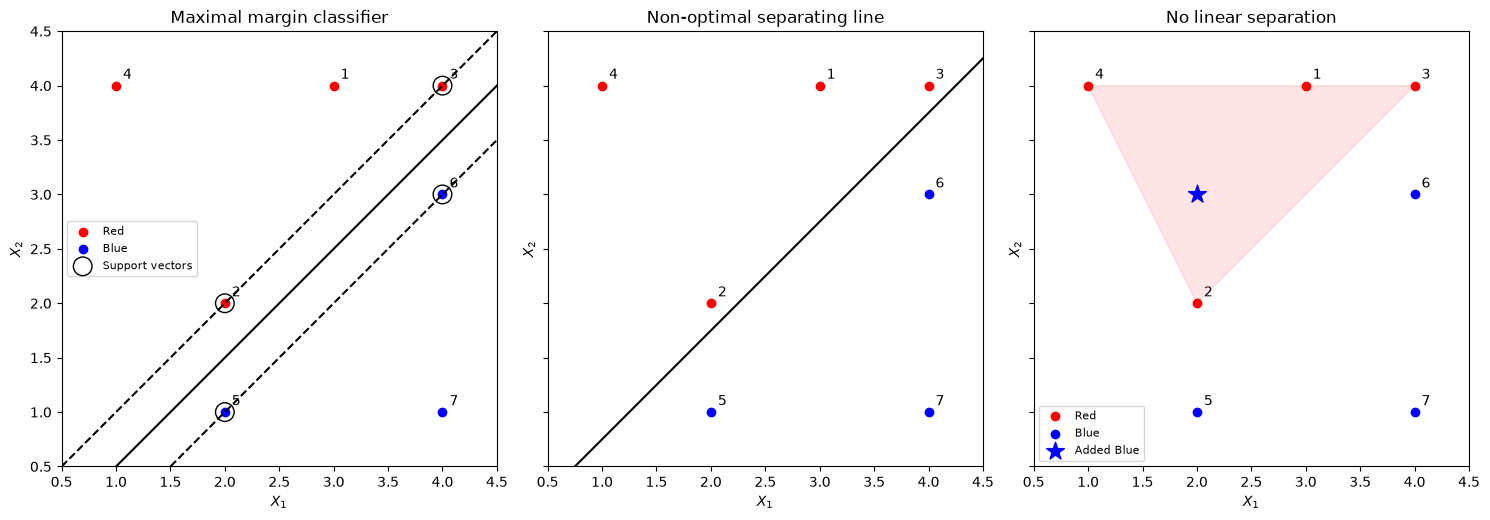

In [11]:
X = np.array([[3, 4], [2, 2], [4, 4], [1, 4],
              [2, 1], [4, 3], [4, 1]])
x = np.array([0.5, 4.5])

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

for ax in axes:
    ax.scatter(X[:4, 0], X[:4, 1], color="red", label="Red")
    ax.scatter(X[4:, 0], X[4:, 1], color="blue", label="Blue")
    for i, (x1, x2) in enumerate(X, 1):
        ax.annotate(str(i), (x1, x2), xytext=(5, 5),
                    textcoords="offset points")
    ax.set(xlim=(0.5, 4.5), ylim=(0.5, 4.5), xlabel="$X_1$", ylabel="$X_2$")
    ax.set_aspect("equal")

axes[0].plot(x, x - 0.5, "k-")
for offset in [0, -1]:
    axes[0].plot(x, x + offset, "k--")

support = X[[1, 2, 4, 5]]
axes[0].scatter(support[:, 0], support[:, 1], s=180,
                facecolors="none", edgecolors="black", label="Support vectors")
axes[0].set_title("Maximal margin classifier")
axes[0].legend(fontsize=8)

axes[1].plot(x, x - 0.25, "k-")
axes[1].set_title("Non-optimal separating line")

axes[2].fill(X[[3, 1, 2], 0], X[[3, 1, 2], 1], color="red", alpha=0.1)
axes[2].scatter(2, 3, color="blue", marker="*", s=180, label="Added Blue")
axes[2].set_title("No linear separation")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

(a) The plots show the seven observations, labeled by observation number and colored by class.

(b) The optimal separating hyperplane is

$$
X_2=X_1-\frac12.
$$

(c) Classify an observation as Red if

$$
\frac12-X_1+X_2>0,
$$

and as Blue otherwise. Thus, $\beta_0=\frac12$, $\beta_1=-1$, and $\beta_2=1$.

(d) The margin boundaries are $X_2=X_1$ and $X_2=X_1-1$. The perpendicular distance from the separating line to either boundary is

$$
M=\frac{1/2}{\sqrt{(-1)^2+1^2}}
=\frac{1}{2\sqrt2}\approx0.354.
$$

(e) The support vectors are observations 2, 3, 5, and 6: $(2,2)$, $(4,4)$, $(2,1)$, and $(4,3)$.

(f) Observation 7 is not a support vector. Small movements that keep it on the Blue side of its margin boundary do not change the optimal separating hyperplane.

(g) One non-optimal separating hyperplane is

$$
X_2=X_1-\frac14.
$$

It separates all observations correctly, but its minimum distance to the observations is $1/(4\sqrt2)$, smaller than the optimal margin.

(h) Add a Blue observation at $(2,3)$. It lies inside the convex hull of the Red observations, so no hyperplane can separate the two classes.